# Appendix experiments

A：密度控制与散度正则实验；B：真实数据 FWL、RSAT 评估。两部分可分别运行，结果保存在各自原有输出目录。


## A. Density-control ablation

每个数据集取前 100 个有效样本，共 300 个样本。先训练启用密度控制的模型，再以其最终高斯数量 $N_{\mathrm{final}}$ 训练关闭密度控制的模型；两组共享事件、训练步数和随机种子，参数独立优化。

训练单元从头运行，每完成一对实验即覆盖保存 `output/APPENDIX_density_control/density-control-ablation-100-samples.json`。绘图单元读取结果并导出平均 RMSE、AEE PDF。


In [1]:
import json
import sys
import time
from dataclasses import asdict, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from tqdm.notebook import tqdm

# 与 utils.painter 中 EXP1/EXP2 的字体及 PDF 嵌入设置保持一致。
plt.rcParams.update({
    "font.family": "Arial",
    "axes.unicode_minus": False,
    "pdf.fonttype": 42,
})


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "generator").is_dir() and (path / "methods").is_dir():
            return path
    raise RuntimeError("Cannot find project root. Please run this notebook inside the project directory.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager
from methods.affinegs.gaussian_flow.config import GaussianFlowConfig
from methods.affinegs.gaussian_flow.training import run_gaussian_flow
from utils.metrics import AEE, RMSE

DENSITY_OUTPUT_DIR = PROJECT_ROOT / "output" / "APPENDIX_density_control"
DENSITY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULT_PATH = DENSITY_OUTPUT_DIR / "density-control-ablation-100-samples.json"

# 与 EXP2 的 Datasets 部分保持一致。
DATA_ROOT = Path("/media/newdisk/datasets_piv/piv_cai/train")
dataset_specs = [
    {"name": "JHTDB-isotropic", "file_prefix": "JHTDB_isotropic1024_hd"},
    {"name": "DNS-turbulence", "file_prefix": "DNS_turbulence"},
    {"name": "SQG", "file_prefix": "SQG"},
]

FLOW_DATA_PATHS = [
    PROJECT_ROOT / "data" / "datasets" / "JHTDB_isotropic1024_hd_00001_flow.npz",
    PROJECT_ROOT / "data" / "datasets" / "DNS_turbulence_00001_flow.npz",
    PROJECT_ROOT / "data" / "datasets" / "SQG_00001_flow.npz",
]
flow_names = [spec["name"] for spec in dataset_specs]
# 后面的散度扫描仍使用原来的流场，首次需要时才加载。
flow_funcs = [None] * len(FLOW_DATA_PATHS)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


CMax fused extension: OK
Using device: cuda
Using device: cuda


In [2]:
seed = 42
samples_per_dataset = 100
file_idx_range = range(1, 1201)
iterations = 300


def set_all_seeds(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed_value)


def select_dataset_samples():
    selected = {}
    for spec in dataset_specs:
        samples = []
        for file_idx in file_idx_range:
            path = DATA_ROOT / f"{spec['file_prefix']}_{file_idx:05d}.npz"
            if not path.is_file():
                continue
            samples.append({"file_idx": file_idx, "file_path": str(path)})
            if len(samples) == samples_per_dataset:
                break
        if len(samples) != samples_per_dataset:
            raise RuntimeError(
                f"{spec['name']}: found {len(samples)} files, need {samples_per_dataset} in {DATA_ROOT}"
            )
        selected[spec["name"]] = samples
    return selected


def make_simulated_event_data(flow_index, flow_source=None):
    # 无显式数据源时，保持后续散度扫描的调用兼容性。
    if flow_source is None:
        if flow_funcs[flow_index] is None:
            flow_funcs[flow_index] = FlowManager(
                mode="data", data_path=str(FLOW_DATA_PATHS[flow_index])
            )
        flow_source = flow_funcs[flow_index]
    cfg_evts = config_events()
    cfg_evts.height, cfg_evts.width = flow_source.field.h, flow_source.field.w
    cfg_evts.time_length = 4.01
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05
    loader = EventManager(
        source_type="simulator", path=None, cfg=cfg_evts,
        flow_func=flow_source.evaluate,
    )
    events, (u, v) = loader.load()
    events = events[(events[:, 2] > 0) & (events[:, 2] < 3)]
    return events, u.cpu().numpy(), v.cpu().numpy()


def evaluate_model(events, cfg, h_gt, w_gt):
    start = time.perf_counter()
    result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
    elapsed = time.perf_counter() - start
    pred_h, pred_w = result.flow
    metrics = {
        "rmse": float(RMSE(pred_h, pred_w, h_gt, w_gt)),
        "aee": float(AEE(pred_h, pred_w, h_gt, w_gt)),
        "num_gaussians": int(result.model.num_gaussians),
        "elapsed_s": float(elapsed),
        "n_history": [int(n) for n in result.history["N"]],
    }
    del result
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return metrics


In [3]:
selected_samples = select_dataset_samples()
base_cfg = GaussianFlowConfig(
    verbose=False, iterations=iterations, init_n=300,
    enable_jacobian=True, enable_density_control=True,
)
# 记录本次运行的配置和样本清单。
ablation_metadata = json.loads(json.dumps({
    "schema_version": 2,
    "data_root": str(DATA_ROOT),
    "samples_per_dataset": samples_per_dataset,
    "selection": "first existing files in ascending index order",
    "seed": seed,
    "event_config": {"time_length": 4.01, "d": 0.5, "density": 0.05,
                     "time_window": [0, 3], "resolution": "from sample"},
    "adaptive_config": asdict(base_cfg),
    "fixed_init": "matched adaptive final Gaussian count",
    "selected_samples": selected_samples,
}))

# 每次执行都重新训练，不读取已有 JSON，也不跳过已完成样本。
ablation_results = {name: [] for name in flow_names}

for flow_index, flow_name in enumerate(tqdm(flow_names, desc="Datasets")):
    rows = ablation_results[flow_name]
    sample_progress = tqdm(selected_samples[flow_name], total=samples_per_dataset,
                           desc=flow_name, leave=False)
    for sample in sample_progress:
        file_idx = sample["file_idx"]
        sample_progress.set_postfix(file=f"{file_idx:05d}", refresh=False)
        # 种子由文件编号确定，重复运行时保持一致。
        event_seed = seed + 10000 * flow_index + file_idx
        set_all_seeds(event_seed)
        flow = FlowManager(mode="data", data_path=sample["file_path"])
        events, h_gt, w_gt = make_simulated_event_data(flow_index, flow_source=flow)
        del flow
        if len(events) == 0:
            raise RuntimeError(f"No events for {flow_name}, file {file_idx:05d}")

        cfg = replace(base_cfg, H=h_gt.shape[0], W=h_gt.shape[1])
        # 两组共享事件和训练随机种子，但各自独立训练。
        train_seed = event_seed + 100000
        set_all_seeds(train_seed)
        adaptive = evaluate_model(events, cfg, h_gt, w_gt)
        final_n = adaptive["num_gaussians"]
        if final_n < 1:
            raise RuntimeError(f"Density control removed all Gaussians: {flow_name}, {file_idx:05d}")

        fixed_cfg = replace(cfg, init_n=final_n, enable_density_control=False)
        set_all_seeds(train_seed)
        fixed = evaluate_model(events, fixed_cfg, h_gt, w_gt)
        assert fixed["num_gaussians"] == final_n
        assert set(fixed["n_history"]) == {final_n}

        rows.append({
            **sample, "event_seed": event_seed, "train_seed": train_seed,
            "resolution": [cfg.H, cfg.W], "num_events": int(len(events)),
            "n_initial": cfg.init_n, "n_final": final_n,
            "adaptive": adaptive, "fixed": fixed,
        })
        # 原子更新：中断时保留上一个完整样本的检查点。
        temporary_path = RESULT_PATH.with_suffix(".json.tmp")
        with open(temporary_path, "w", encoding="utf-8") as f:
            json.dump({"metadata": ablation_metadata, "results": ablation_results},
                      f, ensure_ascii=False, indent=1)
        temporary_path.replace(RESULT_PATH)
        del events, h_gt, w_gt
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f"Saved: {RESULT_PATH}")


Datasets:   0%|          | 0/3 [00:00<?, ?it/s]

JHTDB-isotropic:   0%|          | 0/100 [00:00<?, ?it/s]

DNS-turbulence:   0%|          | 0/100 [00:00<?, ?it/s]

SQG:   0%|          | 0/100 [00:00<?, ?it/s]

Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/density-control-ablation-100-samples.json


JHTDB-isotropic (n=100 distinct samples)
  adaptive N=277.5, RMSE=0.1414, AEE=0.1059, time=0.7s
  fixed    N=277.5, RMSE=0.1559, AEE=0.1143, time=0.7s
DNS-turbulence (n=100 distinct samples)
  adaptive N=300.7, RMSE=0.1352, AEE=0.1031, time=0.7s
  fixed    N=300.7, RMSE=0.1525, AEE=0.1136, time=0.6s
SQG (n=100 distinct samples)
  adaptive N=290.5, RMSE=0.2092, AEE=0.1536, time=0.7s
  fixed    N=290.5, RMSE=0.2373, AEE=0.1682, time=0.6s
Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/density-control-ablation-100-samples-rmse.pdf
Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/density-control-ablation-100-samples-aee.pdf


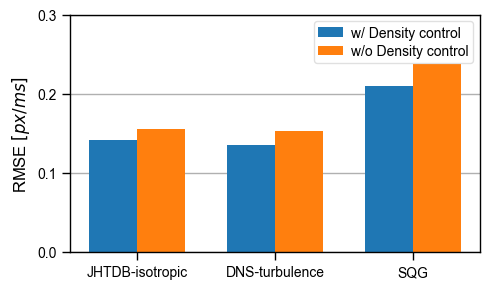

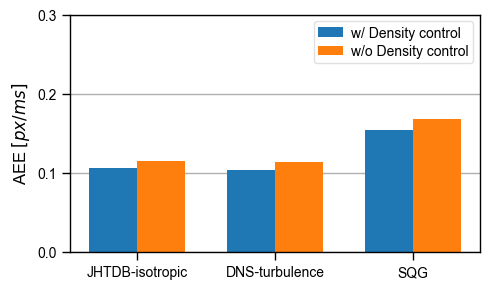

In [ ]:
with open(RESULT_PATH, "r", encoding="utf-8") as f:
    saved = json.load(f)
ablation_results = saved["results"]
expected_samples = saved["metadata"]["selected_samples"]
for name in flow_names:
    rows = ablation_results[name]
    actual = {(row["file_idx"], row["file_path"]) for row in rows}
    expected = {(sample["file_idx"], sample["file_path"]) for sample in expected_samples[name]}
    if len(rows) != saved["metadata"]["samples_per_dataset"] or actual != expected:
        raise RuntimeError(f"{name}: incomplete/duplicate results; finish all samples before plotting.")

summary = {}
for flow_name in flow_names:
    rows = ablation_results[flow_name]
    if not rows:
        continue
    summary[flow_name] = {}
    for method in ("adaptive", "fixed"):
        summary[flow_name][method] = {
            metric: {
                "mean": float(np.mean([row[method][metric] for row in rows])),
                "std": float(np.std([row[method][metric] for row in rows])),
            }
            for metric in ("rmse", "aee", "num_gaussians", "elapsed_s")
        }

for flow_name, methods in summary.items():
    print(f"{flow_name} (n={len(ablation_results[flow_name])} distinct samples)")
    for method, metrics in methods.items():
        print(f"  {method:8s} N={metrics['num_gaussians']['mean']:.1f}, "
              f"RMSE={metrics['rmse']['mean']:.4f}, "
              f"AEE={metrics['aee']['mean']:.4f}, "
              f"time={metrics['elapsed_s']['mean']:.1f}s")

ticks_size = 10
legend_size = 10
label_size = 12

x = np.arange(len(flow_names))
width = 0.35
for metric, title in (("rmse", r"RMSE $[px/ms]$"), ("aee", r"AEE $[px/ms]$")):
    # 与 EXP1/EXP2 的单图尺寸一致。
    fig, ax = plt.subplots(figsize=(5, 3))
    for offset, method, label in [(-width / 2, "adaptive", "w/ Density control"),
                                  (width / 2, "fixed", "w/o Density control")]:
        means = [summary[name][method][metric]["mean"] for name in flow_names]
        ax.bar(x + offset, means, width, label=label)
    ax.set_xticks(x)
    ax.set_xticklabels(flow_names, rotation=0, ha="center")
    # 两张图统一纵轴范围，便于比较。
    ax.set_ylim(0.0, 0.3)
    ax.set_yticks([0.0, 0.1, 0.2, 0.3])
    ax.set_ylabel(title, fontsize=label_size)
    ax.tick_params(axis="both", which="major", labelsize=ticks_size,
                   direction="out", length=6, width=1)
    ax.grid(axis="y", which="major", linestyle="-", linewidth=1)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(1)
    ax.legend(loc="upper right", frameon=True, fontsize=legend_size,
              framealpha=0.6, borderpad=0.3, handlelength=1.8,
              handletextpad=0.6, labelspacing=0.35)
    fig.tight_layout()
    pdf_path = DENSITY_OUTPUT_DIR / f"density-control-ablation-100-samples-{metric}.pdf"
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"Saved: {pdf_path}")
    plt.show()


### Divergence top-ratio sweep

固定 $\lambda=10$，扫描 $p=0,10,\ldots,100\%$，比较速度和散度 RMSE。每次重复共享事件及初始化；散度采用复制边界中心差分。


In [2]:
P_SWEEP_RESULT_PATH = DENSITY_OUTPUT_DIR / "divergence-p-sweep.json"
P_SWEEP_FIGURE_PATH = DENSITY_OUTPUT_DIR / "divergence-p-sweep-rmse.pdf"
p_percent_values = np.arange(0, 101, 10, dtype=int)
p_sweep_repeats = 10
p_sweep_base_seed = 2026
p_sweep_w_div = 10.0


def central_divergence(flow_h, flow_w):
    """与 divergence_regularizer 相同的复制边界中心差分。"""
    flow_h = np.asarray(flow_h, dtype=np.float64)
    flow_w = np.asarray(flow_w, dtype=np.float64)
    h_pad = np.pad(flow_h, ((1, 1), (1, 1)), mode="edge")
    w_pad = np.pad(flow_w, ((1, 1), (1, 1)), mode="edge")
    dflow_h_dh = 0.5 * (h_pad[2:, 1:-1] - h_pad[:-2, 1:-1])
    dflow_w_dw = 0.5 * (w_pad[1:-1, 2:] - w_pad[1:-1, :-2])
    return dflow_h_dh + dflow_w_dw


def flow_and_divergence_rmse(pred_h, pred_w, h_gt, w_gt):
    velocity_rmse = float(RMSE(h_gt, w_gt, pred_h, pred_w))
    pred_div = central_divergence(pred_h, pred_w)
    gt_div = central_divergence(h_gt, w_gt)
    divergence_rmse = float(np.sqrt(np.mean((pred_div - gt_div) ** 2)))
    return velocity_rmse, divergence_rmse


In [6]:
p_sweep_results = {
    "metadata": {
        "p_percent_values": p_percent_values.tolist(),
        "num_repeats": p_sweep_repeats,
        "iterations": iterations,
        "w_div": p_sweep_w_div,
        "paired_events_and_initialization": True,
        "divergence_definition": "d(flow_h)/dh + d(flow_w)/dw",
    },
    "flows": {
        name: {str(int(p)): [] for p in p_percent_values}
        for name in flow_names
    },
}

for flow_index, flow_name in enumerate(tqdm(flow_names, desc="Flows")):
    for repeat in tqdm(range(p_sweep_repeats), desc=f"{flow_name} repeats", leave=False):
        event_seed = p_sweep_base_seed + 1000 * flow_index + repeat
        train_seed = p_sweep_base_seed + 100000 + 1000 * flow_index + repeat

        set_all_seeds(event_seed)
        events, h_gt, w_gt = make_simulated_event_data(flow_index)
        if len(events) == 0:
            raise RuntimeError(f"No events for {flow_name}, repeat {repeat}")

        for p_percent in tqdm(p_percent_values, desc=f"{flow_name} #{repeat}", leave=False):
            cfg = GaussianFlowConfig(
                verbose=False,
                iterations=iterations,
                init_n=300,
                enable_jacobian=True,
                enable_density_control=True,
                lr_j=0.001,
                w_div=p_sweep_w_div,
                div_top_ratio=float(p_percent) / 100.0,
            )

            # 配对初始化：对于同一流场和重复，只有 p 不同。
            set_all_seeds(train_seed)
            result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
            pred_h, pred_w = result.flow[:2]
            velocity_rmse, divergence_rmse = flow_and_divergence_rmse(
                pred_h, pred_w, h_gt, w_gt
            )
            p_sweep_results["flows"][flow_name][str(int(p_percent))].append({
                "repeat": repeat,
                "event_seed": event_seed,
                "train_seed": train_seed,
                "velocity_rmse": velocity_rmse,
                "divergence_rmse": divergence_rmse,
                "num_gaussians": int(result.model.num_gaussians),
            })

            del result
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        with open(P_SWEEP_RESULT_PATH, "w", encoding="utf-8") as f:
            json.dump(p_sweep_results, f, ensure_ascii=False, indent=1)

print(f"Saved: {P_SWEEP_RESULT_PATH}")


Flows:   0%|          | 0/3 [00:00<?, ?it/s]

JHTDB-isotropic repeats:   0%|          | 0/10 [00:00<?, ?it/s]

JHTDB-isotropic #0:   0%|          | 0/11 [00:00<?, ?it/s]

JHTDB-isotropic #1:   0%|          | 0/11 [00:00<?, ?it/s]

JHTDB-isotropic #2:   0%|          | 0/11 [00:00<?, ?it/s]

...

SQG #6:   0%|          | 0/11 [00:00<?, ?it/s]

SQG #7:   0%|          | 0/11 [00:00<?, ?it/s]

SQG #8:   0%|          | 0/11 [00:00<?, ?it/s]

SQG #9:   0%|          | 0/11 [00:00<?, ?it/s]

Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/divergence-p-sweep.json


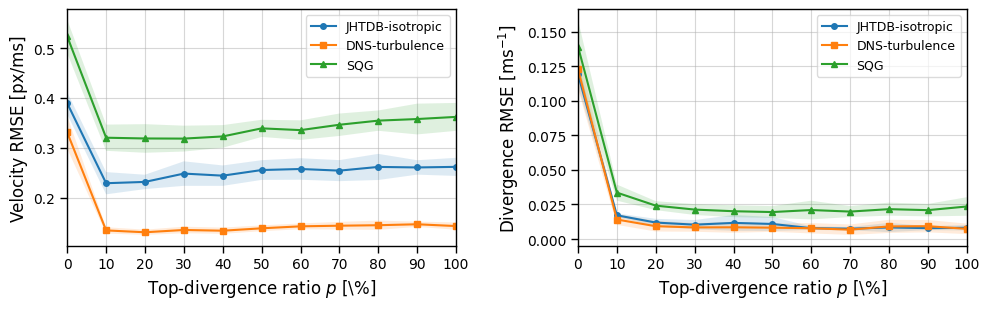

Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/divergence-p-sweep-rmse.pdf
JHTDB-isotropic: best velocity p=10%, best divergence p=70%
DNS-turbulence: best velocity p=20%, best divergence p=70%
SQG: best velocity p=30%, best divergence p=50%


In [7]:
with open(P_SWEEP_RESULT_PATH, "r", encoding="utf-8") as f:
    p_sweep_results = json.load(f)

p_sweep_summary = {name: {} for name in flow_names}
for flow_name in flow_names:
    for p_percent in p_percent_values:
        rows = p_sweep_results["flows"][flow_name][str(int(p_percent))]
        if not rows:
            raise RuntimeError(f"Missing results for {flow_name}, p={p_percent}%")
        p_sweep_summary[flow_name][int(p_percent)] = {
            metric: {
                "mean": float(np.mean([row[metric] for row in rows])),
                "std": float(np.std([row[metric] for row in rows])),
            }
            for metric in ("velocity_rmse", "divergence_rmse")
        }

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
metric_specs = [
    ("velocity_rmse", "Velocity RMSE [px/ms]"),
    ("divergence_rmse", r"Divergence RMSE [ms$^{-1}$]"),
]
markers = ("o", "s", "^")

for ax, (metric, ylabel) in zip(axes, metric_specs):
    for flow_name, marker in zip(flow_names, markers):
        means = np.array([
            p_sweep_summary[flow_name][int(p)][metric]["mean"]
            for p in p_percent_values
        ])
        stds = np.array([
            p_sweep_summary[flow_name][int(p)][metric]["std"]
            for p in p_percent_values
        ])
        ax.plot(p_percent_values, means, marker=marker, linewidth=1.5,
                markersize=4, label=flow_name)
        ax.fill_between(p_percent_values, means - stds, means + stds, alpha=0.15)

    ax.set_xlim(0, 100)
    ax.set_xticks(p_percent_values)
    ax.set_xlabel(r"Top-divergence ratio $p$ [\%]", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(axis="both", which="major", labelsize=10,
                   direction="out", length=5, width=1)
    ax.grid(True, linestyle="-", linewidth=0.8, alpha=0.5)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(1)
    ax.legend(frameon=True, fontsize=9, framealpha=0.7)

fig.tight_layout(w_pad=2.0)
fig.savefig(P_SWEEP_FIGURE_PATH, bbox_inches="tight")
plt.show()
print(f"Saved: {P_SWEEP_FIGURE_PATH}")

for flow_name in flow_names:
    best_velocity_p = min(
        p_percent_values,
        key=lambda p: p_sweep_summary[flow_name][int(p)]["velocity_rmse"]["mean"],
    )
    best_divergence_p = min(
        p_percent_values,
        key=lambda p: p_sweep_summary[flow_name][int(p)]["divergence_rmse"]["mean"],
    )
    print(f"{flow_name}: best velocity p={best_velocity_p}%, "
          f"best divergence p={best_divergence_p}%")


### Divergence-weight sweep

固定 $p=100\%$，扫描 $\lambda=5,10,\ldots,50$。与比例扫描共享事件及初始化；$\lambda=10$ 对应上一组的 $p=100\%$。


In [8]:
W_SWEEP_RESULT_PATH = DENSITY_OUTPUT_DIR / "divergence-weight-sweep.json"
W_SWEEP_FIGURE_PATH = DENSITY_OUTPUT_DIR / "divergence-weight-sweep-rmse.pdf"
w_div_values = np.arange(5, 51, 5, dtype=int)
w_sweep_repeats = 10
w_sweep_base_seed = 2026
w_sweep_top_ratio = 1.0


In [9]:
w_sweep_results = {
    "metadata": {
        "w_div_values": w_div_values.tolist(),
        "div_top_ratio": w_sweep_top_ratio,
        "num_repeats": w_sweep_repeats,
        "iterations": iterations,
        "paired_events_and_initialization": True,
        "divergence_definition": "d(flow_h)/dh + d(flow_w)/dw",
    },
    "flows": {
        name: {str(int(w)): [] for w in w_div_values}
        for name in flow_names
    },
}

for flow_index, flow_name in enumerate(tqdm(flow_names, desc="Flows")):
    for repeat in tqdm(range(w_sweep_repeats), desc=f"{flow_name} repeats", leave=False):
        event_seed = w_sweep_base_seed + 1000 * flow_index + repeat
        train_seed = w_sweep_base_seed + 100000 + 1000 * flow_index + repeat

        set_all_seeds(event_seed)
        events, h_gt, w_gt = make_simulated_event_data(flow_index)
        if len(events) == 0:
            raise RuntimeError(f"No events for {flow_name}, repeat {repeat}")

        for w_div in tqdm(w_div_values, desc=f"{flow_name} #{repeat}", leave=False):
            cfg = GaussianFlowConfig(
                verbose=False,
                iterations=iterations,
                init_n=300,
                enable_jacobian=True,
                enable_density_control=True,
                lr_j=0.001,
                w_div=float(w_div),
                div_top_ratio=w_sweep_top_ratio,
            )

            # 配对初始化：对于同一流场和重复，只有 w_div 不同。
            set_all_seeds(train_seed)
            result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
            pred_h, pred_w = result.flow[:2]
            velocity_rmse, divergence_rmse = flow_and_divergence_rmse(
                pred_h, pred_w, h_gt, w_gt
            )
            w_sweep_results["flows"][flow_name][str(int(w_div))].append({
                "repeat": repeat,
                "event_seed": event_seed,
                "train_seed": train_seed,
                "velocity_rmse": velocity_rmse,
                "divergence_rmse": divergence_rmse,
                "num_gaussians": int(result.model.num_gaussians),
            })

            del result
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        with open(W_SWEEP_RESULT_PATH, "w", encoding="utf-8") as f:
            json.dump(w_sweep_results, f, ensure_ascii=False, indent=1)

print(f"Saved: {W_SWEEP_RESULT_PATH}")


Flows:   0%|          | 0/3 [00:00<?, ?it/s]

JHTDB-isotropic repeats:   0%|          | 0/10 [00:00<?, ?it/s]

JHTDB-isotropic #0:   0%|          | 0/10 [00:00<?, ?it/s]

JHTDB-isotropic #1:   0%|          | 0/10 [00:00<?, ?it/s]

JHTDB-isotropic #2:   0%|          | 0/10 [00:00<?, ?it/s]

...

SQG #6:   0%|          | 0/10 [00:00<?, ?it/s]

SQG #7:   0%|          | 0/10 [00:00<?, ?it/s]

SQG #8:   0%|          | 0/10 [00:00<?, ?it/s]

SQG #9:   0%|          | 0/10 [00:00<?, ?it/s]

Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/divergence-weight-sweep.json


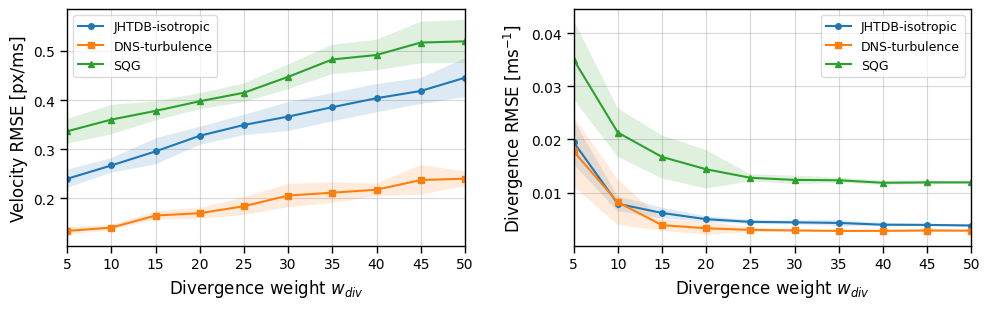

Saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_density_control/divergence-weight-sweep-rmse.pdf
JHTDB-isotropic: best velocity w_div=5, best divergence w_div=50
DNS-turbulence: best velocity w_div=5, best divergence w_div=35
SQG: best velocity w_div=5, best divergence w_div=40


In [10]:
with open(W_SWEEP_RESULT_PATH, "r", encoding="utf-8") as f:
    w_sweep_results = json.load(f)

w_sweep_summary = {name: {} for name in flow_names}
for flow_name in flow_names:
    for w_div in w_div_values:
        rows = w_sweep_results["flows"][flow_name][str(int(w_div))]
        if not rows:
            raise RuntimeError(f"Missing results for {flow_name}, w_div={w_div}")
        w_sweep_summary[flow_name][int(w_div)] = {
            metric: {
                "mean": float(np.mean([row[metric] for row in rows])),
                "std": float(np.std([row[metric] for row in rows])),
            }
            for metric in ("velocity_rmse", "divergence_rmse")
        }

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
metric_specs = [
    ("velocity_rmse", "Velocity RMSE [px/ms]"),
    ("divergence_rmse", r"Divergence RMSE [ms$^{-1}$]"),
]
markers = ("o", "s", "^")

for ax, (metric, ylabel) in zip(axes, metric_specs):
    for flow_name, marker in zip(flow_names, markers):
        means = np.array([
            w_sweep_summary[flow_name][int(w)][metric]["mean"]
            for w in w_div_values
        ])
        stds = np.array([
            w_sweep_summary[flow_name][int(w)][metric]["std"]
            for w in w_div_values
        ])
        ax.plot(w_div_values, means, marker=marker, linewidth=1.5,
                markersize=4, label=flow_name)
        ax.fill_between(w_div_values, means - stds, means + stds, alpha=0.15)

    ax.set_xlim(5, 50)
    ax.set_xticks(w_div_values)
    ax.set_xlabel(r"Divergence weight $w_{div}$", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(axis="both", which="major", labelsize=10,
                   direction="out", length=5, width=1)
    ax.grid(True, linestyle="-", linewidth=0.8, alpha=0.5)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(1)
    ax.legend(frameon=True, fontsize=9, framealpha=0.7)

fig.tight_layout(w_pad=2.0)
fig.savefig(W_SWEEP_FIGURE_PATH, bbox_inches="tight")
plt.show()
print(f"Saved: {W_SWEEP_FIGURE_PATH}")

for flow_name in flow_names:
    best_velocity_w = min(
        w_div_values,
        key=lambda w: w_sweep_summary[flow_name][int(w)]["velocity_rmse"]["mean"],
    )
    best_divergence_w = min(
        w_div_values,
        key=lambda w: w_sweep_summary[flow_name][int(w)]["divergence_rmse"]["mean"],
    )
    print(f"{flow_name}: best velocity w_div={best_velocity_w}, "
          f"best divergence w_div={best_divergence_w}")


### Divergence RMSE versus $p$

读取比例扫描结果，展示散度 RMSE 及相对 $p=0$ 的改善比例。


In [ ]:
DIV_P_RESULT_PATH = DENSITY_OUTPUT_DIR / "divergence-p-sweep.json"
DIV_P_SUMMARY_PATH = DENSITY_OUTPUT_DIR / "divergence-rmse-vs-p-summary.json"
DIV_P_FIGURE_PATH = DENSITY_OUTPUT_DIR / "divergence-rmse-vs-p.pdf"

with open(DIV_P_RESULT_PATH, "r", encoding="utf-8") as f:
    div_p_results = json.load(f)

div_p_values = np.asarray(div_p_results["metadata"]["p_percent_values"], dtype=int)
div_p_summary = {name: {} for name in flow_names}

for flow_name in flow_names:
    baseline_rows = div_p_results["flows"][flow_name][str(int(div_p_values[0]))]
    baseline = np.asarray([row["divergence_rmse"] for row in baseline_rows], dtype=float)

    for p_percent in div_p_values:
        rows = div_p_results["flows"][flow_name][str(int(p_percent))]
        values = np.asarray([row["divergence_rmse"] for row in rows], dtype=float)
        if values.size != baseline.size:
            raise RuntimeError(f"Unpaired repeat count for {flow_name}, p={p_percent}%")
        relative_improvement = 100.0 * (1.0 - values / baseline)
        div_p_summary[flow_name][str(int(p_percent))] = {
            "divergence_rmse_mean": float(values.mean()),
            "divergence_rmse_std": float(values.std()),
            "improvement_vs_p0_percent_mean": float(relative_improvement.mean()),
            "improvement_vs_p0_percent_std": float(relative_improvement.std()),
        }

with open(DIV_P_SUMMARY_PATH, "w", encoding="utf-8") as f:
    json.dump(div_p_summary, f, ensure_ascii=False, indent=1)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
markers = ("o", "s", "^")

for flow_name, marker in zip(flow_names, markers):
    means = np.asarray([
        div_p_summary[flow_name][str(int(p))]["divergence_rmse_mean"]
        for p in div_p_values
    ])
    stds = np.asarray([
        div_p_summary[flow_name][str(int(p))]["divergence_rmse_std"]
        for p in div_p_values
    ])
    improvements = np.asarray([
        div_p_summary[flow_name][str(int(p))]["improvement_vs_p0_percent_mean"]
        for p in div_p_values
    ])
    improvement_stds = np.asarray([
        div_p_summary[flow_name][str(int(p))]["improvement_vs_p0_percent_std"]
        for p in div_p_values
    ])

    axes[0].plot(div_p_values, means, marker=marker, linewidth=1.5,
                 markersize=4, label=flow_name)
    axes[0].fill_between(div_p_values, means - stds, means + stds, alpha=0.15)
    axes[1].plot(div_p_values, improvements, marker=marker, linewidth=1.5,
                 markersize=4, label=flow_name)
    axes[1].fill_between(
        div_p_values, improvements - improvement_stds,
        improvements + improvement_stds, alpha=0.15
    )

axes[0].set_ylabel(r"Divergence RMSE [ms$^{-1}$]", fontsize=12)
axes[1].set_ylabel(r"Improvement over $p=0$ [\%]", fontsize=12)
for ax in axes:
    ax.set_xlim(0, 100)
    ax.set_xticks(div_p_values)
    ax.set_xlabel(r"Top-divergence ratio $p$ [\%]", fontsize=12)
    ax.tick_params(axis="both", which="major", labelsize=10,
                   direction="out", length=5, width=1)
    ax.grid(True, linestyle="-", linewidth=0.8, alpha=0.5)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_linewidth(1)
    ax.legend(frameon=True, fontsize=9, framealpha=0.7)

fig.tight_layout(w_pad=2.0)
fig.savefig(DIV_P_FIGURE_PATH, bbox_inches="tight")
plt.show()

print(f"Saved: {DIV_P_SUMMARY_PATH}")
print(f"Saved: {DIV_P_FIGURE_PATH}")
for flow_name in flow_names:
    best_p = min(
        div_p_values,
        key=lambda p: div_p_summary[flow_name][str(int(p))]["divergence_rmse_mean"],
    )
    best_row = div_p_summary[flow_name][str(int(best_p))]
    print(f"{flow_name}: best p={best_p}%, "
          f"divergence RMSE={best_row['divergence_rmse_mean']:.6f}, "
          f"improvement={best_row['improvement_vs_p0_percent_mean']:.2f}%")


## B. Real-data evaluation

在 EBIV、Water 的 10–20 ms 事件窗口上比较六种方法的 FWL（越大越好）和 RSAT（越小越好）。读取 EXP3 保存的速度场，不重新训练；结果保存至 `output/APPENDIX_real_data_metrics/`。


In [ ]:
import sys
import json
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "generator").is_dir() and (path / "methods").is_dir():
            return path
    raise RuntimeError("Run this notebook inside the project directory.")


PROJECT_ROOT = find_project_root()
FLOW_FIELD_DIR = PROJECT_ROOT / "output" / "EXP3" / "flow_fields"
REAL_OUTPUT_DIR = PROJECT_ROOT / "output" / "APPENDIX_real_data_metrics"
REAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from generator.loader import EventManager

real_device = torch.device("cpu")


In [ ]:
real_flow_index = 1  # 0: EBIV, 1: Water
real_flow_names = ["ebiv", "water"]
cases = [
    dict(source_type="real", path=str(PROJECT_ROOT / "data/real_old/ebiv_wallflow4_dense.h5")),
    dict(source_type="evk5", path=str(PROJECT_ROOT / "data/water.hdf5")),
]
time_window = (10.0, 20.0)

events, _ = EventManager(**cases[real_flow_index]).load()
mask = (events[:, 2] > time_window[0]) & (events[:, 2] < time_window[1])
evts1 = torch.as_tensor(events[mask], dtype=torch.float32, device=real_device)
del events, mask
if len(evts1) == 0:
    raise ValueError("The selected event window is empty.")
print(f"{real_flow_names[real_flow_index]}: {len(evts1):,} events, {time_window[0]:g}–{time_window[1]:g} ms")


### FWL

以窗口中点为参考时刻，计算运动补偿前后 IWE 的方差比，忽略事件极性。使用 `output/EXP3/flow_fields/` 下六种方法的速度场，并校验数据集与事件窗口。


In [ ]:
import json
import torch.nn.functional as F


@torch.no_grad()
def make_fwl_iwe(events, H, W, t_ref, flow=None, chunk_size=100000):
    """Bilinear-splat count IWE; flow channels are (v_h, v_w)."""
    if events.ndim != 2 or events.shape[1] < 3 or len(events) == 0:
        raise ValueError("events must be a nonempty (N, 4) tensor")
    if flow is not None and flow.shape != (2, H, W):
        raise ValueError(f"flow must have shape (2, {H}, {W})")

    iwe = torch.zeros(H * W, device=events.device, dtype=torch.float32)
    for batch in events.split(chunk_size):
        h, w = batch[:, 0].float(), batch[:, 1].float()
        if flow is not None:
            grid = torch.stack((2 * w / (W - 1) - 1, 2 * h / (H - 1) - 1), dim=-1)
            grid = grid.view(1, 1, -1, 2)
            velocity = F.grid_sample(flow[None], grid, mode="bilinear",
                                     padding_mode="border", align_corners=True)[0, :, 0]
            dt = t_ref - batch[:, 2].float()
            h = h + velocity[0] * dt
            w = w + velocity[1] * dt

        inside = (h >= 0) & (h <= H - 1) & (w >= 0) & (w <= W - 1)
        h, w = h[inside], w[inside]
        if h.numel() == 0:
            continue
        h0, w0 = h.floor().long(), w.floor().long()
        h1, w1 = (h0 + 1).clamp(max=H - 1), (w0 + 1).clamp(max=W - 1)
        dh, dw = h - h0, w - w0
        for hi, wh in ((h0, 1 - dh), (h1, dh)):
            for wi, ww in ((w0, 1 - dw), (w1, dw)):
                iwe.index_add_(0, hi * W + wi, wh * ww)

    return iwe.view(H, W)


@torch.no_grad()
def evaluate_fwl(events, v_h, v_w, H, W, t_ref, unwarped_variance):
    flow = torch.stack((torch.as_tensor(v_h, device=events.device, dtype=torch.float32),
                        torch.as_tensor(v_w, device=events.device, dtype=torch.float32)))
    iwe = make_fwl_iwe(events, H, W, t_ref, flow=flow)
    return dict(fwl=float(iwe.var(unbiased=False).item() / unwarped_variance))


In [ ]:
# Load the six velocity fields saved by EXP3.
fwl_method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG", "ConstGS", "AffineGS"]
flow_result_dir = FLOW_FIELD_DIR
flow_result_files = {
    name: flow_result_dir / f"{name}-{real_flow_names[real_flow_index]}.npz"
    for name in fwl_method_names
}
missing_files = [str(path) for path in flow_result_files.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError("Missing saved flow fields:\n" + "\n".join(missing_files))

current_event_count = len(evts1)
current_t_min = float(evts1[:, 2].min().item())
current_t_max = float(evts1[:, 2].max().item())
with np.load(flow_result_files[fwl_method_names[0]], allow_pickle=False) as first_data:
    H, W = int(first_data["H"]), int(first_data["W"])

t_ref = 0.5 * (current_t_min + current_t_max)
unwarped_iwe = make_fwl_iwe(evts1, H, W, t_ref)
unwarped_variance = float(unwarped_iwe.var(unbiased=False).item())
if unwarped_variance <= 0:
    raise ValueError("Unwarped IWE has zero variance; FWL is undefined.")
del unwarped_iwe

fwl_results = {}
for name, flow_file in flow_result_files.items():
    with np.load(flow_file, allow_pickle=False) as data:
        flow = np.asarray(data["flow"], dtype=np.float32)
        saved_method = str(data["method_name"].item())
        saved_flow_name = str(data["flow_name"].item())
        saved_H, saved_W = int(data["H"]), int(data["W"])
        saved_event_count = int(data["event_count"])
        saved_t_min = float(data["t_min"])
        saved_t_max = float(data["t_max"])

    if saved_method != name or saved_flow_name != real_flow_names[real_flow_index]:
        raise ValueError(f"Metadata mismatch in {flow_file}")
    if (saved_H, saved_W) != (H, W) or flow.shape != (2, H, W):
        raise ValueError(f"Flow shape mismatch in {flow_file}: {flow.shape}")
    if (saved_event_count != current_event_count or
            not np.isclose(saved_t_min, current_t_min, atol=1e-6) or
            not np.isclose(saved_t_max, current_t_max, atol=1e-6)):
        raise ValueError(f"Event-window mismatch in {flow_file}; rerun {name}.")

    fwl_results[name] = evaluate_fwl(
        evts1, flow[0], flow[1], H, W, t_ref, unwarped_variance
    )
    print(f"{name:>10s}: FWL={fwl_results[name]['fwl']:.4f}")
    del flow
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

fwl_summary = dict(flow=real_flow_names[real_flow_index], image_size=[H, W],
                   event_count=len(evts1), t_ref=t_ref, methods=fwl_results)
fwl_output_file = REAL_OUTPUT_DIR / f"FWL-{real_flow_names[real_flow_index]}.json"
with open(fwl_output_file, "w") as f:
    json.dump(fwl_summary, f, indent=2)
print(f"saved: {fwl_output_file}")


saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_real_data_metrics/FWL-table-water.pdf


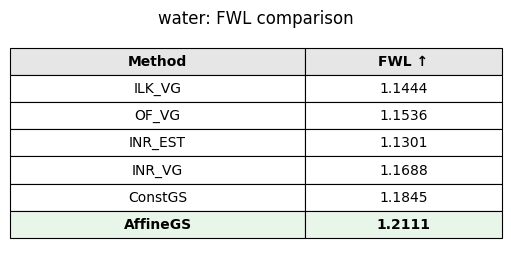

In [ ]:
table_method_names = [name for name in fwl_method_names if name in fwl_results]
table_rows = [
    [name, f"{fwl_results[name]['fwl']:.4f}"]
    for name in table_method_names
]
best_row = max(range(len(table_method_names)),
               key=lambda i: fwl_results[table_method_names[i]]["fwl"])

fig, ax = plt.subplots(figsize=(5, 2.5))
ax.axis("off")
ax.set_title(f"{real_flow_names[real_flow_index]}: FWL comparison", fontsize=12, pad=8)
table = ax.table(
    cellText=table_rows,
    colLabels=["Method", "FWL ↑"],
    cellLoc="center", colLoc="center", loc="center",
    colWidths=[0.60, 0.40],
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.0, 1.45)
for col in range(2):
    table[(0, col)].set_facecolor("#E6E6E6")
    table[(0, col)].get_text().set_weight("bold")
    table[(best_row + 1, col)].set_facecolor("#E8F5E9")
    table[(best_row + 1, col)].get_text().set_weight("bold")
for cell in table.get_celld().values():
    cell.set_edgecolor("black")
    cell.set_linewidth(0.8)

fig.tight_layout(pad=0.3)
fwl_table_file = REAL_OUTPUT_DIR / f"FWL-table-{real_flow_names[real_flow_index]}.pdf"
fig.savefig(fwl_table_file, bbox_inches="tight")
print(f"saved: {fwl_table_file}")
plt.show()


### RSAT

将事件补偿到窗口终点，分别构建正、负极性的平均时间戳图；时间戳归一化到 [0, 1]，其能量相对零流基线的比值为 RSAT。


In [ ]:
@torch.no_grad()
def make_rsat_energy(events, H, W, t_ref, flow=None, chunk_size=100000, eps=1e-9):
    """Build polarity-separated average-timestamp images and return their energy."""
    if events.ndim != 2 or events.shape[1] < 4:
        raise ValueError("events must have shape (N, >=4): [row, col, time, polarity].")
    if len(events) == 0:
        raise ValueError("RSAT cannot be evaluated with an empty event window.")

    device = events.device
    dtype = torch.float32
    t_min = float(events[:, 2].min().item())
    t_max = float(events[:, 2].max().item())
    duration = t_max - t_min
    if duration <= 0:
        raise ValueError("RSAT requires a non-zero event-window duration.")

    if flow is not None:
        flow = torch.as_tensor(flow, dtype=dtype, device=device)
        if tuple(flow.shape) != (2, H, W):
            raise ValueError(f"flow must have shape (2, {H}, {W}), got {tuple(flow.shape)}.")

    count_pos = torch.zeros(H * W, dtype=dtype, device=device)
    count_neg = torch.zeros_like(count_pos)
    time_pos = torch.zeros_like(count_pos)
    time_neg = torch.zeros_like(count_pos)

    for start in range(0, len(events), chunk_size):
        batch = events[start:start + chunk_size]
        h = batch[:, 0].to(dtype)
        w = batch[:, 1].to(dtype)
        t = batch[:, 2].to(dtype)
        positive = batch[:, 3] > 0

        if flow is not None:
            grid_w = 2.0 * w / max(W - 1, 1) - 1.0
            grid_h = 2.0 * h / max(H - 1, 1) - 1.0
            grid = torch.stack((grid_w, grid_h), dim=-1).view(1, -1, 1, 2)
            sampled_flow = torch.nn.functional.grid_sample(
                flow.unsqueeze(0), grid, mode="bilinear",
                padding_mode="border", align_corners=True,
            ).view(2, -1)
            dt = float(t_ref) - t
            h = h + sampled_flow[0] * dt
            w = w + sampled_flow[1] * dt

        inside = (h >= 0) & (h <= H - 1) & (w >= 0) & (w <= W - 1)
        if not inside.any():
            continue
        h, w, t, positive = h[inside], w[inside], t[inside], positive[inside]
        t_norm = (t - t_min) / duration

        h0 = torch.floor(h).long()
        w0 = torch.floor(w).long()
        h1 = torch.clamp(h0 + 1, max=H - 1)
        w1 = torch.clamp(w0 + 1, max=W - 1)
        dh = h - h0.to(dtype)
        dw = w - w0.to(dtype)

        neighbours = (
            (h0, w0, (1.0 - dh) * (1.0 - dw)),
            (h0, w1, (1.0 - dh) * dw),
            (h1, w0, dh * (1.0 - dw)),
            (h1, w1, dh * dw),
        )
        for hh, ww, weight in neighbours:
            index = hh * W + ww
            if positive.any():
                idx = index[positive]
                wei = weight[positive]
                count_pos.index_add_(0, idx, wei)
                time_pos.index_add_(0, idx, wei * t_norm[positive])
            negative = ~positive
            if negative.any():
                idx = index[negative]
                wei = weight[negative]
                count_neg.index_add_(0, idx, wei)
                time_neg.index_add_(0, idx, wei * t_norm[negative])

    occupied = (count_pos + count_neg) > eps
    occupied_pixels = int(occupied.sum().item())
    if occupied_pixels == 0:
        raise RuntimeError("No warped event remained inside the image.")

    avg_time_pos = time_pos / (count_pos + eps)
    avg_time_neg = time_neg / (count_neg + eps)
    energy = (avg_time_pos.square().sum() + avg_time_neg.square().sum()) / occupied_pixels
    return float(energy.item())


@torch.no_grad()
def evaluate_rsat(events, v_h, v_w, H, W, t_ref, zero_energy):
    flow = torch.stack((
        torch.as_tensor(v_h, dtype=torch.float32, device=events.device),
        torch.as_tensor(v_w, dtype=torch.float32, device=events.device),
    ))
    energy = make_rsat_energy(events, H, W, t_ref, flow=flow)
    return {"rsat": energy / max(float(zero_energy), 1e-12)}


In [ ]:
# Load the same saved EXP3 velocity fields used by FWL.
import json

rsat_method_names = ["ILK_VG", "OF_VG", "INR_EST", "INR_VG", "ConstGS", "AffineGS"]
rsat_flow_name = real_flow_names[real_flow_index]
rsat_flow_field_dir = FLOW_FIELD_DIR
rsat_result_files = {
    name: rsat_flow_field_dir / f"{name}-{rsat_flow_name}.npz"
    for name in rsat_method_names
}
missing = [str(path) for path in rsat_result_files.values() if not path.exists()]
if missing:
    raise FileNotFoundError(
        "Missing saved velocity fields. Run the corresponding methods in EXP3 first:\\n"
        + "\n".join(missing)
    )

current_event_count = int(len(evts1))
current_t_min = float(evts1[:, 2].min().item())
current_t_max = float(evts1[:, 2].max().item())
rsat_t_ref = current_t_max
rsat_results = {}

with np.load(rsat_result_files[rsat_method_names[0]], allow_pickle=False) as first_saved:
    H, W = int(first_saved["H"]), int(first_saved["W"])
zero_energy = make_rsat_energy(evts1, H, W, rsat_t_ref, flow=None)

for name, result_file in rsat_result_files.items():
    with np.load(result_file, allow_pickle=False) as saved:
        saved_method = str(saved["method_name"].item())
        saved_flow_name = str(saved["flow_name"].item())
        saved_H, saved_W = int(saved["H"]), int(saved["W"])
        saved_event_count = int(saved["event_count"])
        saved_t_min, saved_t_max = float(saved["t_min"]), float(saved["t_max"])
        if saved_method != name or saved_flow_name != rsat_flow_name:
            raise ValueError(f"Metadata mismatch in {result_file}.")
        if (saved_H, saved_W) != (H, W):
            raise ValueError(f"Image-size mismatch in {result_file}.")
        if saved_event_count != current_event_count or not np.allclose(
            [saved_t_min, saved_t_max], [current_t_min, current_t_max], rtol=0, atol=1e-9
        ):
            raise ValueError(f"Event-window mismatch in {result_file}; rerun {name} above.")
        flow = saved["flow"].astype(np.float32)

    rsat_results[name] = evaluate_rsat(
        evts1, flow[0], flow[1], H, W, rsat_t_ref, zero_energy
    )
    print(f"{name:>8s}: RSAT={rsat_results[name]['rsat']:.6f}")

rsat_summary = {
    "flow_name": rsat_flow_name,
    "event_count": current_event_count,
    "t_min": current_t_min,
    "t_max": current_t_max,
    "reference_time": "t_max",
    "timestamp_normalization": "(t - t_min) / (t_max - t_min)",
    "methods": rsat_results,
}
rsat_output_file = REAL_OUTPUT_DIR / f"RSAT-{rsat_flow_name}.json"
with open(rsat_output_file, "w") as f:
    json.dump(rsat_summary, f, indent=2)
print(f"saved: {rsat_output_file}")


saved: /media/newdisk/junjie/2dGS-representation/output/APPENDIX_real_data_metrics/RSAT-table-water.pdf


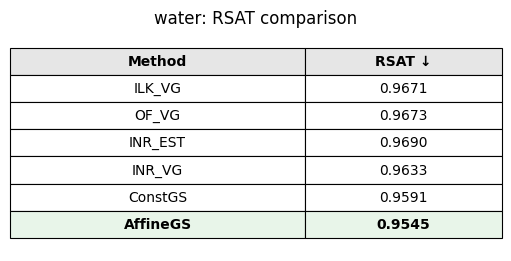

In [ ]:
rsat_table_names = [name for name in rsat_method_names if name in rsat_results]
rsat_table_rows = [
    [name, f"{rsat_results[name]['rsat']:.4f}"]
    for name in rsat_table_names
]
best_row = min(range(len(rsat_table_names)),
               key=lambda i: rsat_results[rsat_table_names[i]]["rsat"])

fig, ax = plt.subplots(figsize=(5, 2.5))
ax.axis("off")
ax.set_title(f"{rsat_flow_name}: RSAT comparison", fontsize=12, pad=8)
table = ax.table(
    cellText=rsat_table_rows,
    colLabels=["Method", "RSAT ↓"],
    cellLoc="center", colLoc="center", loc="center",
    colWidths=[0.60, 0.40],
)
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.0, 1.45)
for col in range(2):
    table[(0, col)].set_facecolor("#E6E6E6")
    table[(0, col)].get_text().set_weight("bold")
    table[(best_row + 1, col)].set_facecolor("#E8F5E9")
    table[(best_row + 1, col)].get_text().set_weight("bold")
for cell in table.get_celld().values():
    cell.set_edgecolor("black")
    cell.set_linewidth(0.8)

fig.tight_layout(pad=0.3)
rsat_table_file = REAL_OUTPUT_DIR / f"RSAT-table-{rsat_flow_name}.pdf"
fig.savefig(rsat_table_file, bbox_inches="tight")
print(f"saved: {rsat_table_file}")
plt.show()
